# Neural PDE Exercises · 01
## From observations to a PDE loss

**Course section:** From data to PDE solvers. **Time:** 35–50 minutes.
This notebook is self-contained: select **Restart Kernel and Run All Cells** in a
fresh Python 3.11+ kernel. CPU / float64; the supplied run is a working baseline.

[All practical exercises](README.md) · [Laboratory guide](../NOTEBOOK_README.md) ·
[Related laboratory](../Neural_PDE_01_foundations.ipynb)

**How to work:** predict the outcome, run the baseline, then edit the marked
settings and rerun all cells. Keep a small results table and answer the reflection
questions. Use the same seed and training budget when comparing methods.

**Notation:** $u$ is the reference state, $u_\theta$ the neural state,
$r_\theta=\mathcal L u_\theta-f$, $\widehat{\mathcal J}$ a sampled loss,
and $\mathcal E$ an energy. Reference values are used for checking errors after
training, except when observations are explicitly supplied.

## 1 · Predict before computing

On $(0,1)$, solve $-u''=\pi^2\sin(\pi x)$ with $u(0)=u(1)=0$.
A few noisy measurements are available. Compare two identical networks with the
hard boundary factor $u_\theta=x(1-x)N_\theta(x)$:

$$\widehat{\mathcal J}_{\mathrm{data}}=\frac1m\sum_i|u_\theta(x_i)-y_i|^2,
\qquad
\widehat{\mathcal J}_{\mathrm{hybrid}}=
\widehat{\mathcal J}_{\mathrm{data}}+
\alpha\frac1n\sum_j|r_\theta(z_j)/\pi^2|^2.$$

**Predict:** which fit will be more sensitive to noisy observations? Does a PDE
constraint guarantee improvement if the supplied forcing is incorrect?

In [1]:
import copy
import math
import time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import torch
from torch import nn

SEED = 7
torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
palette = {"navy": "#10243A", "teal": "#00A6A6", "orange": "#F28C45",
           "pink": "#DC4778", "blue": "#4878D0", "ink": "#183449", "muted": "#63788A"}
plt.rcParams.update({
    "figure.facecolor": "#F7FAFC", "axes.facecolor": "#F7FAFC",
    "axes.edgecolor": "#CAD6DF", "axes.labelcolor": palette["ink"],
    "text.color": palette["ink"], "xtick.color": palette["muted"],
    "ytick.color": palette["muted"], "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#DCE5EB", "grid.alpha": 0.65,
    "lines.linewidth": 2.3, "figure.dpi": 100, "legend.frameon": False,
    "axes.prop_cycle": matplotlib.cycler(color=[palette[k] for k in
                                 ["teal", "orange", "pink", "blue", "navy"]]),
})

def network(width=20, activation=nn.Tanh):
    return nn.Sequential(nn.Linear(1, width), activation(),
                         nn.Linear(width, width), activation(), nn.Linear(width, 1))

class State(nn.Module):
    def __init__(self, initial, hard=True):
        super().__init__()
        self.net, self.hard = copy.deepcopy(initial), hard
    def forward(self, x):
        raw = self.net(x)
        return x*(1-x)*raw if self.hard else raw

def derivative(value, x):
    return torch.autograd.grad(value.sum(), x, create_graph=True)[0]

def forcing(x):
    return math.pi**2 * torch.sin(math.pi*x)

def residual(model, points):
    x = points.detach().clone().requires_grad_(True)
    u = model(x)
    return -derivative(derivative(u, x), x) - forcing(x)

def train(model, objective, steps=500, lr=0.004):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    started = time.perf_counter()
    for step in range(steps):
        optimizer.zero_grad(set_to_none=True)
        loss = objective(model)
        loss.backward()
        optimizer.step()
        history.append(float(loss.detach()))
    assert np.isfinite(history).all(), "The optimizer produced a non-finite objective."
    return np.asarray(history), time.perf_counter()-started

# This independent grid is never passed to a training objective.
check_x = torch.linspace(0, 1, 503).reshape(-1, 1)
check_u = torch.sin(math.pi*check_x).numpy().ravel()
boundary_x = torch.tensor([[0.0], [1.0]])

def diagnostics(model):
    with torch.no_grad():
        prediction = model(check_x).numpy().ravel()
        boundary_error = float(model(boundary_x).abs().max())
    scaled_residual = residual(model, check_x).detach().numpy().ravel()/math.pi**2
    relative_l2 = np.linalg.norm(prediction-check_u)/np.linalg.norm(check_u)
    return {"prediction": prediction, "relative_l2": float(relative_l2),
            "residual_rms": float(np.sqrt(np.mean(scaled_residual**2))),
            "boundary_max": boundary_error}

print(f"CPU / float64 / seed {SEED} / PyTorch {torch.__version__}")

CPU / float64 / seed 7 / PyTorch 2.10.0


In [2]:
# EDIT HERE: vary one setting at a time and record all four values.
SENSOR_X = [0.15, 0.40, 0.80]
NOISE_STD = 0.06
PDE_WEIGHT = 1.0
STEPS = 500

sensor_x = torch.tensor(SENSOR_X).reshape(-1, 1)
sensor_y = torch.sin(math.pi*sensor_x) + NOISE_STD*torch.tensor(
    rng.normal(size=(len(SENSOR_X), 1)))
collocation_x = torch.linspace(0, 1, 50)[1:-1].reshape(-1, 1)
initial = network()
models, histories, reports = {}, {}, {}
for name, weight in [("Observations", 0.0), ("Observations + PDE", PDE_WEIGHT)]:
    model = State(initial)
    def objective(candidate, weight=weight):
        data_loss = (candidate(sensor_x)-sensor_y).square().mean()
        if weight == 0:
            return data_loss
        return data_loss + weight*(residual(candidate, collocation_x)/math.pi**2).square().mean()
    history, seconds = train(model, objective, steps=STEPS)
    report = diagnostics(model)
    with torch.no_grad():
        report["sensor_rmse"] = float((model(sensor_x)-sensor_y).square().mean().sqrt())
    models[name], histories[name], reports[name] = model, history, report
    print(f"{name:20s} | sensor RMSE {report['sensor_rmse']:.3e} | "
          f"relative L2 {report['relative_l2']:.3e} | {seconds:.1f} s")

Observations         | sensor RMSE 3.138e-02 | relative L2 3.537e-02 | 0.2 s


Observations + PDE   | sensor RMSE 1.301e-02 | relative L2 2.567e-03 | 0.6 s


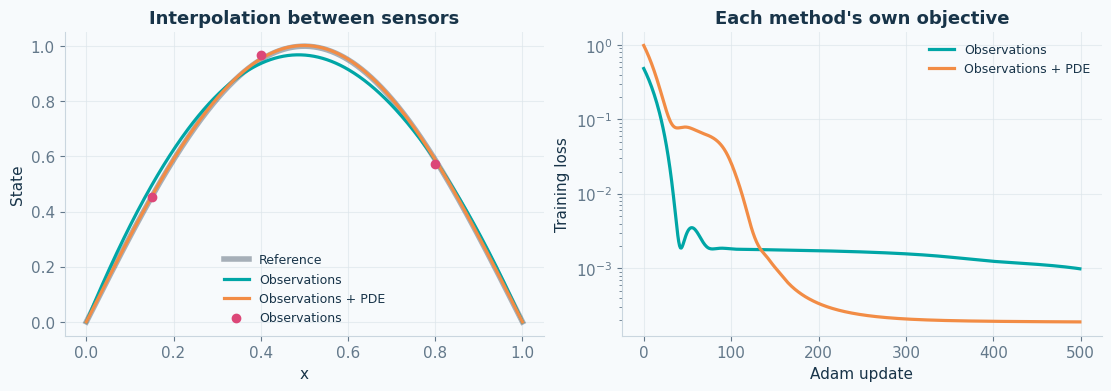

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
axes[0].plot(check_x, check_u, color=palette["navy"], alpha=.35, lw=4, label="Reference")
for name, report in reports.items():
    axes[0].plot(check_x, report["prediction"], label=name)
    axes[1].semilogy(histories[name], label=name)
axes[0].scatter(SENSOR_X, sensor_y.numpy(), color=palette["pink"], zorder=5, label="Observations")
axes[0].set(title="Interpolation between sensors", xlabel="x", ylabel="State")
axes[1].set(title="Each method's own objective", xlabel="Adam update", ylabel="Training loss")
for ax in axes:
    ax.grid(); ax.legend(fontsize=9)
plt.show()
assert all(v["boundary_max"] == 0.0 for v in reports.values())
assert all(np.isfinite(v["relative_l2"]) for v in reports.values())

## 2 · Your experiment

1. Compare noise levels `0.0`, `0.06`, and `0.15` with the same sensors and seed.
   Record sensor RMSE and independent relative L2 error for both methods.
2. Move all sensors into `[0.1, 0.4]`. Predict the error outside that region before
   rerunning. Keep the held-out grid out of the objective.
3. Sweep `PDE_WEIGHT` through `0.01`, `1.0`, and `100.0`. Plot solution error
   against the weight; the two training objectives have different scales.

**Hint:** the smallest sensor error may correspond to a fit to observation noise.
The PDE adds information about the field between the observed locations.

## 3 · Checks and reflection

The checks confirm finite diagnostics and the exact endpoint constraint; they do
not require one training method to win for every seed. Explain why that would be
an inappropriate assertion. Identify what is known in this experiment: forcing,
boundary values, observation locations, and observed values.

**Deliverable:** one results table, one annotated plot, and three sentences
explaining when the PDE term helps and what happens if the model is misspecified.